# Experimental Pytorch Project 
Owner: Chidubem

This is a notebook to practice making models with Pytorch

 Used to create the project environment and install packages
1. ! python3 -m venv .venv
2. ! pip3 install torch numpy matplotlib

In [ ]:
# ! python3 -m venv .venv
# ! pip3 install torch numpy matplotlib

In [1]:
import torch
import torch.nn as nn
from torchvision.transforms import v2
from torchvision import datasets
from torch.utils.data import DataLoader, Dataset, random_split
import numpy as np
import time

Rock, Paper, Scissors dataset from [Deeplearning.AI](https://creativecommons.org/licenses/by/2.0/).
1. Define a path to the images
2. Transform the image data using [torchvision.v2](https://docs.pytorch.org/vision/stable/transforms.html)
2. Use a Pytorch [ImageFolder](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html) class to create a dataset from images

In [2]:
DATA_DIR = './rps'
TRAIN_SPLIT = 0.1
BATCH_SIZE = 128

# Returns PIL image
data_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((180,180)),
    v2.Grayscale(num_output_channels=1)
])

crop = v2.RandomResizedCrop(180,(0.5,1))

preprocessing = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(45)
])

data = datasets.ImageFolder(DATA_DIR, transform = data_transforms)

print(f"Training classes = {data.class_to_idx}")

train_dataset, validation_dataset = random_split(data,[1-TRAIN_SPLIT, TRAIN_SPLIT])

Training classes = {'paper': 0, 'rock': 1, 'scissors': 2}


Generate a preprocessed training dataset and a not preprocessed validation dataset

In [3]:
class Split_Dataset(Dataset):
    def __init__(self, dataset, preprocessing=None, crop=None):
        super().__init__()
        self.data = []
        self.labels = []
        for x,y in dataset:
            self.data.append(x)
            self.labels.append(y)
        self.preprocessing = preprocessing
        self.crop = crop

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        x = self.data[index]
        y = self.labels[index]
        if self.crop:
            x = self.crop(x)
        if self.preprocessing:
            x = self.preprocessing(x)
        return x, y

train_dataset = Split_Dataset(train_dataset, preprocessing, crop)
validation_dataset = Split_Dataset(validation_dataset)

dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=len(validation_dataset))

print(f'Train dataset: {len(train_dataset)}\nVal Dataset {len(validation_dataset)}')

print(f'Input shape: {train_dataset[0][0].shape}\nMax input val: {train_dataset[0][0].max()}')

Train dataset: 2268
Val Dataset 252
Input shape: torch.Size([1, 180, 180])
Max input val: 0.9999000430107117


In [4]:
print(f'Number training batchs: {len(dataloader)}\nNumber validation batches: {len(val_loader)}')

Number training batchs: 18
Number validation batches: 1


Plotting the dataset images before and after transformations to check the outcome

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


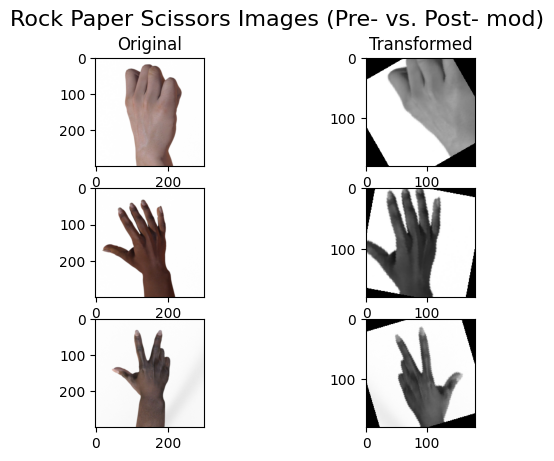

In [5]:
import matplotlib.pyplot as plt
import os
from PIL import Image

fig, axes = plt.subplots(3,2)
fig.suptitle('Rock Paper Scissors Images (Pre- vs. Post- mod)', fontsize=16)
axes[0,0].set_title('Original')

axes[0,1].set_title('Transformed')

# Use a modified transformation function to take in PIL image as input and output the modified image
dummy_transform = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((180,180)),
    v2.Grayscale(num_output_channels=1),
    v2.ToTensor()
])

for i, label in enumerate(['rock','paper','scissors']):
    dir = os.path.join(DATA_DIR,label)
    img_path = dir+'/'+os.listdir(dir)[0]
    img = Image.open(img_path)
    trans_img = dummy_transform(img)
    trans_img = crop(trans_img)
    aug_img = preprocessing(trans_img)
    aug_img = aug_img.squeeze(0)

    axes[i,0].imshow(img)
    axes[i,1].imshow(aug_img,cmap ='gray')

## Creating the Classification Model

1. Define the model class (layers, forward)
2. Choose loss and optimizer
3. Create training loop

In [7]:
# Define my CNN class
class RPSNeuralNet(nn.Module):
    def __init__(self, input_shape, hidden_size, num_classes):
        super(RPSNeuralNet,self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(input_shape[0],32,kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2,stride=2),
            nn.Conv2d(32,32,kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2,stride=2),
            nn.Flatten()
        )

        self.reduced_h_dim = int((((input_shape[1]-2)//2)-2)//2)
        self.reduced_w_dim = int((((input_shape[2]-2)//2)-2)//2)

        print(f'Reduced dims (h,w): {(self.reduced_h_dim,self.reduced_w_dim)}\n')

        self.classifier = nn.Sequential(
            nn.Linear(32*self.reduced_h_dim*self.reduced_w_dim, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_size,num_classes)
        )

    def forward(self,x):
        x = self.features(x)
        out = self.classifier(x)
        return out

    def train_all(self):
        for param in self.parameters():
            param.requires_grad_()

    def __str__(self):
        return 'RPSNeuralNet'

    def summary(self): # Summarize
        print(nn.Module.__str__(self) + '\n')

        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in model.parameters())

        print(f'{trainable_params} trainable parameters, {total_params} total parameters\n')

# Second CNN class
class RPSNeuralNetv2(nn.Module):
    def __init__(self, input_shape, hidden_size, num_classes):
        super(RPSNeuralNetv2,self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(input_shape[0],32,kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(4,stride=4),
            nn.Flatten()
        )

        self.reduced_h_dim = int((input_shape[1]-2)//4)
        self.reduced_w_dim = int((input_shape[2]-2)//4)

        print(f'Reduced dims (h,w): {(self.reduced_h_dim,self.reduced_w_dim)}\n')

        self.classifier = nn.Sequential(
            nn.Linear(32*self.reduced_h_dim*self.reduced_w_dim, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_size,num_classes)
        )

    def forward(self,x):
        x = self.features(x)
        out = self.classifier(x)
        return out

    def train_all(self):
        for param in self.parameters():
            param.requires_grad_()

    def __str__(self):
        return 'RPSNeuralNetv2'

    def summary(self): # Summarize
        print(nn.Module.__str__(self) + '\n')

        trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        total_params = sum(p.numel() for p in model.parameters())

        print(f'{trainable_params} trainable parameters, {total_params} total parameters\n')

Create model and save state to file 'model.dct'

In [18]:
import gc

# Clear references
try:
    del model
except NameError:
    print('Model not defined')

try:
    del optimizer
except NameError:
    print('Optimizer not defined')

# Run Python garbage collection
gc.collect()

# Clear MPS memory cache
torch.mps.empty_cache()

input_shape = (1, 180, 180) # (num channels, h, w)
output_size = 3
hidden_size = 128

model = RPSNeuralNet(input_shape, hidden_size, output_size)

model.summary()

Reduced dims (h,w): (43, 43)

RPSNeuralNet(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=59168, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=3, bias=True)
  )
)

7583587 trainable parameters, 7583587 total parameters



Reinitialize the RPSNeuralNet Models

In [ ]:
model.__init__(input_shape, hidden_size, output_size)

## Training loop 

Check if Mac GPU devices available

In [9]:
print('Mac GPU available:', torch.backends.mps.is_available())

Mac GPU available: True


In [19]:
class SavingCheckpoint():
    def __init__(self,
                 model: nn.Module, # model
                 optimizer:torch.optim.Optimizer, # optimizer
                 targ_loss=None, # target loss
                 targ_acc=None, #
                 stops_training=False): # target accuracy
        '''
        Args:

        model: a nn.Module type object

        optimizer: a torch.optim.Optimizer type object

        targ_loss: target loss

        targ_acc: target accuracy

        stops_training: meeting criteria stops training

        '''

        self.model = model
        self.optimizer = optimizer
        self.targ_loss = targ_loss
        self.targ_acc = targ_acc
        self.stops_training=stops_training

    def __call__(self, loss=None, acc=None, **kwargs): # decide if checkpoint should run
        if self.targ_loss is not None and loss is not None:
            if self.targ_loss >= loss: # loss checkpoint
                self.set_targ_loss(loss)
                return self.save_checkpoint(loss, **kwargs)
        if self.targ_acc is not None and acc is not None: # accuracy checkpoint
            if self.targ_acc <= acc:
                self.set_targ_acc(acc)
                return self.save_checkpoint(loss, **kwargs)

    def save_checkpoint(self, loss, **kwargs):
        checkpoint_data = {
            'epoch': kwargs['epoch'],
            'model_state_dict': self.model.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'loss': loss,
            'history': kwargs['history']
            }

        # Make sure that the parent directory exists before trying to save
        torch.save(checkpoint_data, kwargs['dir'])
        print(f'{self.model} saved')
        return self.stops_training

    def set_targ_acc(self, acc):
        self.targ_acc = acc

    def set_targ_loss(self, loss):
        self.targ_loss = loss

class EarlyStoppingCheckpoint(SavingCheckpoint):
    def __init__(self, model, optimizer, targ_loss=None, targ_acc=None):
        super().__init__(model, optimizer, targ_loss, targ_acc, stops_training=True)

Run cell below to train a new model

In [21]:
learning_rate = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

In [37]:
def load_checkpoint(dir):
    if os.path.exists(dir):
        checkpoint_data = torch.load(dir, weights_only=True)
        optimizer.load_state_dict(checkpoint_data['optimizer_state_dict'])
        model.load_state_dict(checkpoint_data['model_state_dict'])
        curr_epoch = checkpoint_data['epoch']
        history = checkpoint_data['history']
        print(f'Last epoch: {curr_epoch}, loss: {checkpoint_data['loss']}')
        return curr_epoch, history
    else:
        print('Invalid path')
        return None

def save_checkpoint(dir: str, epoch=0):
    checkpoint_data = {
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': history['loss'][-1],
                'history': history
            }

    # Make sure that the parent directory exists before trying to save
    torch.save(checkpoint_data, dir)
    print(f'Checkpoint saved to {dir}')

In [44]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

parent_dir = 'RPSNNv1_trained' # make '' to set parent to current directory
if not os.path.exists(parent_dir) and parent_dir != '': # Create parent directory
    os.mkdir(parent_dir)

training_path = os.path.join(parent_dir,'model_checkpoint_rpsnnv1_(3).pt') # edit the path to file of your choice
num_epochs = 100
if os.path.exists(training_path):
    curr_epoch, history = load_checkpoint(training_path) # set to 0, history if training a new model/optimizer
else:
    curr_epoch = 1 # set to 0, history if training a new model/optimizer
model.to(device)

early_stop_cp = EarlyStoppingCheckpoint(model=model, optimizer=optimizer, targ_acc=0.97)
saving_cp =  SavingCheckpoint(model=model, optimizer=optimizer, targ_acc=0.95)
checkpoints = [early_stop_cp, saving_cp]

Last epoch: 83, loss: 0.30913900635229846


In [43]:
model.train()

while curr_epoch <= num_epochs:

    stop_training = False
    running_loss, total = 0.0, 0
    correct = 0
    time_per_step, duration = 0.0, 0.0

    for (x, y) in dataloader: # Training loop
        start = time.perf_counter()

        optimizer.zero_grad()

        x, y= x.to(device), y.to(device)

        outputs = model(x)
        loss = criterion(outputs,y)
        loss.backward()
        optimizer.step()

        duration += time.perf_counter() - start

        _, preds = outputs.max(1)
        correct += (preds == y).sum().item()

        running_loss += loss.item() * x.size(0)
        total += y.size(0)

    running_val_loss, val_total = 0.0, 0
    val_correct = 0

    with torch.no_grad(): # Validation
        for (x, y) in val_loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            val_loss = criterion(outputs,y)

            _, val_preds = outputs.max(1)
            val_correct += (val_preds == y).sum().item()

            running_val_loss += val_loss.item() * x.size(0)
            val_total += y.size(0)

    time_per_step = duration/len(dataloader)
    history['loss'].append(running_loss/total)
    history['accuracy'].append(correct/total)
    history['val_loss'].append(running_val_loss/val_total)
    history['val_accuracy'].append(val_correct/val_total)

    # if (epoch+1)%10 == 0:
    print(f'Epoch {curr_epoch}/{num_epochs} --> time per step: {int(time_per_step*1000)}ms, loss: {history['loss'][-1]:.4f}, accuracy: {history['accuracy'][-1]:.4f}, val loss: {history['val_loss'][-1]:.4f}, val accuracy: {history['val_accuracy'][-1]:.4f}')

    metrics = {
        'epoch': curr_epoch,
        'dir': training_path,
        'history': history
    }

    for checkpt in checkpoints:
        if checkpt(history['loss'][-1], history['val_accuracy'][-1], **metrics):
            stop_training = True
            break

    if stop_training:
        print(f'\nTraining stopped at epoch {curr_epoch}: loss: {history['loss'][-1]:.4f}, accuracy: {history['accuracy'][-1]:.4f}')
        break

    curr_epoch += 1

if not os.path.exists(training_path):
    save_checkpoint(training_path, curr_epoch)

Epoch 83/100 --> time per step: 11ms, loss: 0.2320, accuracy: 0.9162, val loss: 0.3162, val accuracy: 0.8611
Epoch 84/100 --> time per step: 5ms, loss: 0.2619, accuracy: 0.9065, val loss: 0.2680, val accuracy: 0.8889
Epoch 85/100 --> time per step: 5ms, loss: 0.2432, accuracy: 0.9136, val loss: 0.2225, val accuracy: 0.8968
Epoch 86/100 --> time per step: 4ms, loss: 0.2444, accuracy: 0.9092, val loss: 0.2608, val accuracy: 0.8810
Epoch 87/100 --> time per step: 5ms, loss: 0.2420, accuracy: 0.9149, val loss: 0.2279, val accuracy: 0.9008
Epoch 88/100 --> time per step: 5ms, loss: 0.2448, accuracy: 0.9145, val loss: 0.1974, val accuracy: 0.9127
Epoch 89/100 --> time per step: 4ms, loss: 0.2295, accuracy: 0.9171, val loss: 0.3121, val accuracy: 0.8770
Epoch 90/100 --> time per step: 4ms, loss: 0.2514, accuracy: 0.9096, val loss: 0.2678, val accuracy: 0.8810
Epoch 91/100 --> time per step: 4ms, loss: 0.2421, accuracy: 0.9118, val loss: 0.1828, val accuracy: 0.9286
Epoch 92/100 --> time per s

In [ ]:
# Uncomment to manually save a model
# save_checkpoint('model_checkpoint_rpsnnv2_(2).pt', curr_epoch)

Checkpoint saved to model_checkpoint_rpsnnv2_(2).pt


## Plot training loss & accuracy

Evaluate model performance

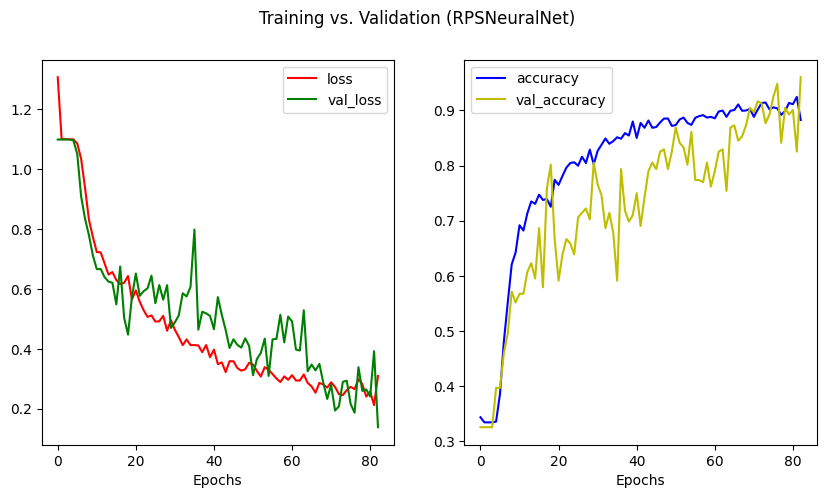

In [31]:
from datetime import datetime, timezone

epochs = np.arange(len(history['loss']))

def plot_history(history: dict, epochs):
    fig, ax = plt.subplots(1, 2, figsize=(10,5))
    colors = ['r','b','g','y','p']

    for i, (label, data) in enumerate(history.items()):
        if 'accuracy' in label:
            ax[1].plot(epochs, data, colors[i], label=label)
            ax[1].legend()
            ax[1].set_xlabel('Epochs')
        else:
            ax[0].plot(epochs, data, colors[i], label=label)
            ax[0].legend()
            ax[0].set_xlabel('Epochs')

    fig.suptitle(f'Training vs. Validation ({model})')

plot_history(history, epochs)

# Save to a designated file
plt.savefig(os.path.join(parent_dir,f'{model}_metrics_{datetime.now(timezone.utc).date()}.png'))

Create a test dataset to evaluate the model on unseen RPS images with presumably novel features

In [26]:
TEST_DIR = 'rps-test-set'

test_dataset = datasets.ImageFolder(TEST_DIR, transform=data_transforms)
test_loader = DataLoader(test_dataset,len(test_dataset))

In [32]:
model.to('cpu')
model.eval()

with torch.no_grad():
    running_loss, total = 0.0, 0
    correct = 0

    for (x, y) in test_loader:
        x, y = x.to('cpu'), y.to('cpu')
        outputs = model(x)
        loss = criterion(outputs,y)

        _, preds = outputs.max(1)
        correct += (preds == y).sum().item()
        running_loss += loss.item() * x.size(0)
        total += y.size(0)

print(f'Test loss = {running_loss/total}, Test accuracy = {correct/total}')

Test loss = 0.16598212718963623, Test accuracy = 0.9597855227882037


In [ ]:
CHECKPOINT_PATH = 'model_checkpoint_rpsnnv1_(2).pt'
checkpoint = torch.load(CHECKPOINT_PATH, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])

## TRY IT OUT!

Collect an image from a URL, import to the img variable, and collect model output

In [33]:
from PIL import Image

def guess_rps():
    model.to('cpu')

    while True:
        model.eval()
        path = input('Type image filenames with space in between (type "exit" to break): ')

        if path.lower() == 'exit':
            break

        try:
            for path in path.split(' '):
                with Image.open(os.path.join('example-images', path)) as img:
                    plt.imshow(img)
                    trans_img = dummy_transform(img)
                    trans_img = trans_img.unsqueeze(0)
                    with torch.no_grad():
                        outputs = model(trans_img)
                    _, pred = outputs.max(1)
                    plt.title(f"This is a {test_dataset.classes[pred.item()]}!\n\n")
                    plt.show()
        except:
            print('Invalid path')
            continue

In [36]:
guess_rps()

Invalid path
Invalid path
